# Energy Markets Quantitative Analysis — Lecture 7: Machine learning for energy markets
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies; Romanian Academy, Institute for Economic Forecasting

This notebook reproduces the models, numbers and charts of Lecture 7 from the real data in `../data/clean` (see `../data/SOURCES.md`) and the benchmark forecasts of Lecture 2 (`../lectures/L2/cache/forecasts.pkl`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

**Rules used everywhere.** The forecast for delivery day *d* is made at 12:00 CET on *d−1*: prices are known up to *d−1*; realised load, wind, solar, hydro, nuclear and flows only up to *d−2*; carbon at the *d−2* close. Three samples in time order: training, a validation year (to choose settings) and the test year of Lecture 2 (to report). Seeds are fixed.

**Running time.** By default the heavy runs are read from the cache written by `analysis_L7.py`; each section re-runs one monthly refit live and checks that it reproduces the cache. Set `RUN_ALL = True` in §1 to recompute everything (about 10 minutes on 16 cores).

## §1 Data, information set and the three samples

In [ ]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/notebooks')

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle, json, time, warnings
from scipy import stats
from joblib import Parallel, delayed
warnings.filterwarnings('ignore')
RUN_ALL = False          # True: recompute every search and forecast (about 10 minutes on 16 cores)
DATA = '../data/clean/'
TZ = 'Europe/Brussels'
SEED = 20261106
N_JOBS = -1

PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
CB = pd.read_csv(DATA + 'crossborder_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', index_col=0)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', index_col=0)
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')['eua_etc_co2l_eur_per_unit']
raw_last = min(PD['RO'].dropna().index.max(), G['hydro_run_of_river'].dropna().index.max())
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2022-01-01')
print('cut-off (last complete month):', END.date())

cut-off (last complete month): 2026-10-31


In [2]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


PM_ALL, _ = day_matrix(HP['RO'].dropna())
PM, DST = day_matrix(HP['RO'].dropna())
LM, _ = day_matrix(GH['load'].dropna())
RM, _ = day_matrix((GH['wind_onshore'] + GH['solar']).dropna())
CAL = pd.date_range(START, END, freq='D')
PM, LM, RM = PM.reindex(CAL), LM.reindex(CAL), RM.reindex(CAL)
CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq='D')
FUND_RAW = pd.DataFrame({'hydro': (G['hydro_run_of_river'] + G['hydro_water_reservoir']).reindex(CAL_EX),
                         'nuclear': G['nuclear'].reindex(CAL_EX), 'netimp': CB['sum'].reindex(CAL_EX), 'eua': EUA.reindex(CAL_EX)})
FUND_AVAIL = FUND_RAW.ffill().shift(2).reindex(CAL)        # past values only, lagged 2 days
P_, L_, R_, F_ = (x.values.astype(float) for x in (PM, LM, RM, FUND_AVAIL))
DOW = CAL.dayofweek.values; IDX = {t: i for i, t in enumerate(CAL)}
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)
FIRST = 7
TEST0 = END - pd.Timedelta(days=364); VAL0 = TEST0 - pd.Timedelta(days=365)
TDAYS = pd.date_range(TEST0, END, freq='D'); VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq='D')
print('training from', CAL[FIRST].date(), '| validation', VAL0.date(), '-', VDAYS[-1].date(), '| test', TEST0.date(), '-', END.date())

training from 2022-01-08 | validation 2024-11-01 - 2025-10-31 | test 2025-11-01 - 2026-10-31


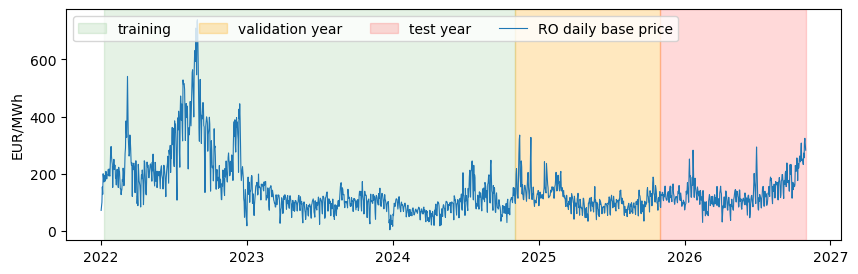

In [3]:
def blocks_of(days, freq="M"):
    """(first row, last row) of each calendar month (or quarter) of a day range."""
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period(freq)):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


MB = blocks_of(TDAYS, 'M')                         # 12 monthly refits in the test year
_vm = blocks_of(VDAYS, 'M'); VB = [(_vm[k][0], _vm[k + 2][1]) for k in range(0, 12, 3)]   # 4 refits in the validation year
A = P_[[IDX[t] for t in TDAYS]]; AV = P_[[IDX[t] for t in VDAYS]]
fig, ax = plt.subplots(figsize=(10, 3))
ax.axvspan(CAL[FIRST], VAL0, color='g', alpha=0.1, label='training'); ax.axvspan(VAL0, TEST0, color='orange', alpha=0.25, label='validation year')
ax.axvspan(TEST0, END, color='r', alpha=0.15, label='test year'); ax.plot(PM.mean(1), lw=0.8, label='RO daily base price')
ax.set_ylabel('EUR/MWh'); ax.legend(ncol=4, loc='upper left'); plt.show()

**Benchmarks of Lecture 2.** The forecasts of the naive model, AW-ARX, AW-LEAR and of the ensemble of 4 are read from the cache of Lecture 2 (same test year, same information set) and checked against its published MAE.

In [4]:
FC2 = pickle.load(open('../lectures/L2/cache/forecasts.pkl', 'rb'))
N2 = json.load(open('../lectures/L2/L2_numbers.json'))
nb = N2['design']['n_burn']
B = {k: v[nb:] for k, v in FC2['point'].items()}
B['aw_arx'] = np.mean([B[f'arx{T}'] for T in (56, 84, 112, 714, 721, 728)], 0)
B['aw_lear'] = np.mean([B[f'lear{T}'] for T in (364, 546, 728)], 0)
B['gbm2'], B['mlp2'] = FC2['gbm'], FC2['mlp']
B['ens4'] = np.mean([B['aw_arx'], B['aw_lear'], B['gbm2'], B['mlp2']], 0)
mae = lambda F: np.mean(np.abs(A - F))
for k in ['naive', 'aw_arx', 'aw_lear', 'ens4']: print(f'{k:8s} MAE {mae(B[k]):6.2f}')
assert abs(mae(B['aw_lear']) - N2['acc']['aw_lear']['mae']) < 0.006

naive    MAE  27.82
aw_arx   MAE  22.30
aw_lear  MAE  22.53
ens4     MAE  22.13


## §2 Deep neural network: architecture, training, early stopping and random search

The functions below are copied from `analysis_L7.py`. `dnn_block` fits on all days before the block, chooses the number of epochs on the last 15% of the training days (chronological early stopping), refits on all days and forecasts the block.

In [5]:
def dnn_inputs(Pa, La, Ra, Fa, rows, sc, cfg):
    """Input vector of day d (rows): asinh-scaled prices of d-1, d-2, (d-3), d-7 (24 h each), load and wind+solar of d-2, d-3, d-7,
    the 4 daily fundamentals of d-2 and day-of-week dummies. Returns the matrix and the column range of each block."""
    m, s, mL, sL, mR, sR = sc
    cols, names = [], []
    for k in PLAGS:
        if k == 3 and not cfg["p3"]:
            continue
        cols.append(np.arcsinh((shift_rows(Pa, k)[rows] - m) / s))
        names += [f"price d-{k}"] * 24
    if cfg["load"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(La, k)[rows] - mL) / sL))
            names += ["load"] * 24
    if cfg["res"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR))
            names += ["wind+solar"] * 24
    if cfg["fund"]:
        cols.append(Fa[rows])
        names += ["hydro", "nuclear", "net imports", "carbon"]
    cols.append(np.eye(7)[DOW[rows]])
    names += ["day of week"] * 7
    return np.column_stack(cols), np.array(names)


def _net(n_in, cfg):
    import torch.nn as nn
    act = nn.ReLU if cfg["act"] == "relu" else nn.Softplus
    layers, prev = [], n_in
    for h in [cfg["n1"]] + ([cfg["n2"]] if cfg["n2"] else []):
        layers += [nn.Linear(prev, h), act(), nn.Dropout(cfg["drop"])]
        prev = h
    layers.append(nn.Linear(prev, 24))
    return nn.Sequential(*layers)


def _train(X, Y, cfg, seed, epochs, Xv=None, yv_eur=None, m=0.0, s=1.0, patience=25):
    """Mini-batch Adam on the mean absolute error of the asinh price; L1 penalty on the input layer (Lago et al. 2021).
    With a validation block: returns the epoch with the lowest validation MAE (EUR/MWh) and the learning curves."""
    import torch
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    Xt, Yt = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    net = _net(X.shape[1], cfg)
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    first = net[0].weight
    curve_tr, curve_v, best, best_ep, since = [], [], np.inf, 1, 0
    for ep_ in range(1, epochs + 1):
        net.train()
        perm = rng.permutation(len(X))
        for b0 in range(0, len(X), cfg["batch"]):
            ix = perm[b0:b0 + cfg["batch"]]
            opt.zero_grad()
            loss = (net(Xt[ix]) - Yt[ix]).abs().mean() + cfg["l1"] * first.abs().sum() / first.numel()
            loss.backward()
            opt.step()
        if Xv is not None:
            net.eval()
            with torch.no_grad():
                ptr = m + s * np.sinh(net(Xt).numpy())
                pv = m + s * np.sinh(net(torch.tensor(Xv, dtype=torch.float32)).numpy())
            curve_tr.append(float(np.mean(np.abs(ptr - (m + s * np.sinh(Y))))))
            v = float(np.mean(np.abs(pv - yv_eur)))
            curve_v.append(v)
            if v < best - 1e-9:
                best, best_ep, since = v, ep_, 0
            else:
                since += 1
                if since >= patience:
                    break
    net.eval()
    return net, best_ep, curve_tr, curve_v


def dnn_block(Pa, La, Ra, Fa, i0, i1, cfg, seeds=(1,), max_ep=300, keep=False, lo=FIRST):
    """Fit on target rows lo..i0-1 (all before the block), forecast rows i0..i1.
    Step 1: transforms from rows up to the start of the early-stopping block; train on the first 85% of the training days,
    early-stop on the last 15% (chronological). Step 2: transforms from all training rows; refit for the chosen number of
    epochs on all training days; forecast. Seeds averaged."""
    import torch
    torch.set_num_threads(1)
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]
    sc0 = (*mad_scale(Pa[lo:v0]), *mad_scale(La[lo:v0 - 1]), *mad_scale(Ra[lo:v0 - 1]))
    X0, _ = dnn_inputs(Pa, La, Ra, Fa, tr, sc0, cfg)
    Y0 = np.arcsinh((Pa[tr] - sc0[0]) / sc0[1])
    mu0, sg0 = X0[:cut].mean(0), X0[:cut].std(0)
    sg0[sg0 == 0] = 1
    sc = (*mad_scale(Pa[tr]), *mad_scale(La[lo:i0 - 1]), *mad_scale(Ra[lo:i0 - 1]))
    X, names = dnn_inputs(Pa, La, Ra, Fa, tr, sc, cfg)
    Y = np.arcsinh((Pa[tr] - sc[0]) / sc[1])
    mu, sg = X.mean(0), X.std(0)
    sg[sg == 0] = 1
    te = np.arange(i0, i1 + 1)
    Xte, _ = dnn_inputs(Pa, La, Ra, Fa, te, sc, cfg)
    preds, epochs, curves, models = [], [], [], []
    for sd in seeds:
        _, best_ep, ctr, cv = _train((X0[:cut] - mu0) / sg0, Y0[:cut], cfg, sd, max_ep, (X0[cut:] - mu0) / sg0,
                                     Pa[tr[cut:]], sc0[0], sc0[1])
        net, _, _, _ = _train((X - mu) / sg, Y, cfg, sd, best_ep)
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((Xte - mu) / sg, dtype=torch.float32)).numpy()))
        epochs.append(best_ep)
        curves.append((ctr, cv))
        if keep:
            models.append({k: v.clone() for k, v in net.state_dict().items()})
    out = {"pred": np.mean(preds, 0), "epochs": epochs, "sec": time.perf_counter() - t0, "n_seeds": len(seeds)}
    if keep:
        out.update({"models": models, "mu": mu, "sg": sg, "sc": sc, "names": names, "curves": curves})
    return out


def dnn_predict_from(state, cfg, X, mu, sg, sc):
    import torch
    torch.set_num_threads(1)
    preds = []
    for st in state:
        net = _net(X.shape[1], cfg)
        net.load_state_dict(st)
        net.eval()
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((X - mu) / sg, dtype=torch.float32)).numpy()))
    return np.mean(preds, 0)


def dnn_space(n=24, seed=SEED):
    rng = np.random.default_rng(seed)
    out = [{"n1": 128, "n2": 64, "act": "relu", "drop": 0.0, "lr": 1e-3, "wd": 1e-3, "l1": 0.0, "batch": 64,
            "load": True, "res": True, "fund": True, "p3": True}]
    for _ in range(n):
        out.append({"n1": int(rng.choice([64, 128, 256, 512])), "n2": int(rng.choice([0, 32, 64, 128, 256])),
                    "act": str(rng.choice(["relu", "softplus"])), "drop": float(rng.choice([0.0, 0.1, 0.2, 0.3])),
                    "lr": float(rng.choice([3e-4, 1e-3, 3e-3])), "wd": float(rng.choice([0.0, 1e-5, 1e-4, 1e-3])),
                    "l1": float(rng.choice([0.0, 1e-3, 1e-2, 1e-1])), "batch": int(rng.choice([32, 64, 128])),
                    "load": bool(rng.random() < 0.5), "res": bool(rng.random() < 0.5), "fund": bool(rng.random() < 0.5),
                    "p3": bool(rng.random() < 0.5)})
    return out

validation MAE: best 22.59 (setting 17), Lecture 2 setting 24.24
chosen: {'n1': 512, 'n2': 0, 'act': 'softplus', 'drop': 0.1, 'lr': 0.0003, 'wd': 1e-05, 'l1': 0.0, 'batch': 64, 'load': True, 'res': True, 'fund': True, 'p3': True}


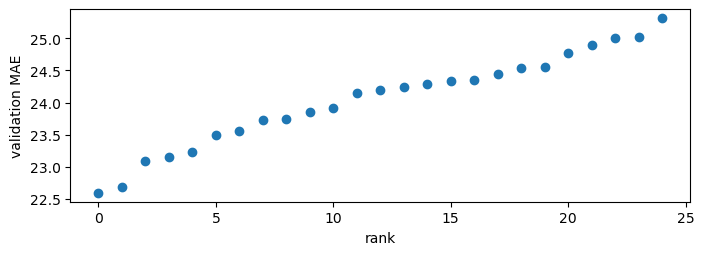

In [6]:
DNN_SPACE = dnn_space()
CACHE = '../lectures/L7/cache/ml.pkl'
if RUN_ALL:
    r = Parallel(n_jobs=N_JOBS)(delayed(dnn_block)(P_, L_, R_, F_, a, b, cfg) for cfg in DNN_SPACE for a, b in VB)
    DNN_VAL = [np.vstack([r[c * 4 + j]['pred'] for j in range(4)]) for c in range(len(DNN_SPACE))]
else:
    Cc = pickle.load(open(CACHE, 'rb'))
    DNN_VAL = Cc['dnn_val_pred']
VAL_DNN = np.array([np.mean(np.abs(AV - p)) for p in DNN_VAL])
BEST_DNN = int(np.argmin(VAL_DNN)); CFG_DNN = DNN_SPACE[BEST_DNN]
print('validation MAE: best %.2f (setting %d), Lecture 2 setting %.2f' % (VAL_DNN.min(), BEST_DNN, VAL_DNN[0]))
print('chosen:', CFG_DNN)
plt.figure(figsize=(8, 2.5)); plt.plot(np.sort(VAL_DNN), 'o'); plt.ylabel('validation MAE'); plt.xlabel('rank'); plt.show()

**Live check.** Refit the chosen network for the last test month with 4 seeds and compare with the cache; then draw the learning curve of seed 1.

refit in 9.4 s, epochs kept per seed: [51, 39, 66, 52]
max |live - cached| = 0.00000 EUR/MWh


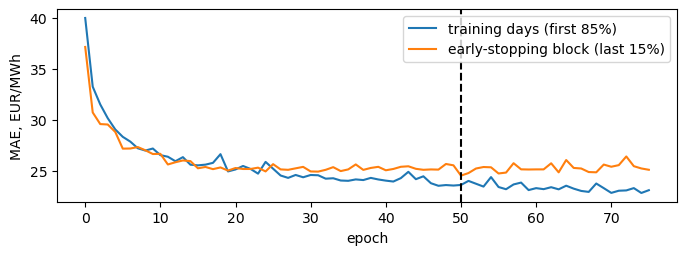

In [7]:
a, b = MB[-1]
t0 = time.time(); r = dnn_block(P_, L_, R_, F_, a, b, CFG_DNN, (1, 2, 3, 4), keep=True)
print('refit in %.1f s, epochs kept per seed:' % (time.time() - t0), r['epochs'])
if not RUN_ALL:
    print('max |live - cached| = %.5f EUR/MWh' % np.max(np.abs(r['pred'] - Cc['dnn_main'][-1]['pred'])))
ctr, cv = r['curves'][0]
plt.figure(figsize=(8, 2.5)); plt.plot(ctr, label='training days (first 85%)'); plt.plot(cv, label='early-stopping block (last 15%)')
plt.axvline(np.argmin(cv), ls='--', color='k'); plt.ylabel('MAE, EUR/MWh'); plt.xlabel('epoch'); plt.legend(); plt.show()

## §3 Gradient boosting (XGBoost)

In [8]:
XGB_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)', 'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)', 'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']


def gbm_rows(Pa, La, Ra, Fa, rows, leak=False):
    """Long-format features for (day, hour) pairs (the 20 features of the L2 GBM). leak=True adds the realised load and
    wind+solar of the delivery hour itself (NOT known at gate closure: used only to measure the look-ahead pitfall)."""
    P1, P2, P3, P7 = (shift_rows(Pa, k) for k in PLAGS)
    L2_, L7_, R2_, R7_ = shift_rows(La, 2), shift_rows(La, 7), shift_rows(Ra, 2), shift_rows(Ra, 7)
    feats = []
    for h in range(24):
        f = [P1[rows, h], P2[rows, h], P3[rows, h], P7[rows, h], P1[rows, 23], P1[rows].min(1), P1[rows].max(1),
             P1[rows].mean(1), L2_[rows, h], L7_[rows, h], R2_[rows, h], R7_[rows, h], L2_[rows].mean(1),
             R2_[rows].mean(1), Fa[rows], np.full(len(rows), h), DOW[rows]]
        if leak:
            f += [La[rows, h], Ra[rows, h]]
        feats.append(np.column_stack(f))
    return np.stack(feats, 1)


def _xgb(cfg, seed):
    import xgboost as xgb
    return xgb.XGBRegressor(n_estimators=cfg["n_est"], learning_rate=cfg["eta"], max_depth=cfg["depth"],
                            min_child_weight=cfg["mcw"], subsample=cfg["sub"], colsample_bytree=cfg["col"],
                            reg_lambda=cfg["lam"], objective=cfg["obj"], tree_method="hist", n_jobs=1, random_state=seed,
                            max_leaves=cfg.get("leaves", 0), grow_policy=cfg.get("grow", "depthwise"))


def xgb_block(Pa, La, Ra, Fa, i0, i1, cfg, seed=SEED, lo=FIRST, leak=False, shap=False):
    """Fit on target rows lo..i0-1, forecast rows i0..i1. Target = asinh((P-m)/s), m and s from the training prices."""
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    m, s = mad_scale(Pa[tr])
    p = len(XGB_NAMES) + (2 if leak else 0)
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr, leak).reshape(-1, p)
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = _xgb(cfg, seed).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    Xte = gbm_rows(Pa, La, Ra, Fa, te, leak).reshape(-1, p)
    y = mdl.predict(Xte).reshape(len(te), 24)
    out = {"pred": m + s * np.sinh(y), "sec": time.perf_counter() - t0}
    if shap:
        import xgboost as xgb
        con = mdl.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)      # exact SHAP values (Lundberg et al. 2020)
        out.update({"shap": con.reshape(len(te), 24, p + 1), "m": m, "s": s, "X": Xte.reshape(len(te), 24, p)})
    return out


def xgb_space(n=24, seed=SEED + 1):
    rng = np.random.default_rng(seed)
    out = [{"n_est": 500, "eta": 0.05, "depth": 0, "leaves": 31, "grow": "lossguide", "mcw": 40, "sub": 1.0, "col": 1.0,
            "lam": 1.0, "obj": "reg:squarederror"}]
    for _ in range(n):
        out.append({"n_est": int(rng.choice([300, 600, 1000, 1500])), "eta": float(rng.choice([0.02, 0.05, 0.1])),
                    "depth": int(rng.choice([3, 4, 5, 6, 8])), "mcw": int(rng.choice([1, 5, 20, 50])),
                    "sub": float(rng.choice([0.6, 0.8, 1.0])), "col": float(rng.choice([0.6, 0.8, 1.0])),
                    "lam": float(rng.choice([0.1, 1.0, 10.0])),
                    "obj": str(rng.choice(["reg:squarederror", "reg:absoluteerror", "reg:pseudohubererror"]))})
    return out

In [9]:
XGB_SPACE = xgb_space()
if RUN_ALL:
    r = Parallel(n_jobs=N_JOBS)(delayed(xgb_block)(P_, L_, R_, F_, a, b, cfg) for cfg in XGB_SPACE for a, b in VB)
    XGB_VAL = [np.vstack([r[c * 4 + j]['pred'] for j in range(4)]) for c in range(len(XGB_SPACE))]
else:
    XGB_VAL = Cc['xgb_val_pred']
VAL_XGB = np.array([np.mean(np.abs(AV - p)) for p in XGB_VAL])
BEST_XGB = int(np.argmin(VAL_XGB)); CFG_XGB = XGB_SPACE[BEST_XGB]
print('validation MAE: best %.2f, Lecture 2 setting %.2f' % (VAL_XGB.min(), VAL_XGB[0])); print('chosen:', CFG_XGB)
a, b = MB[-1]; r = xgb_block(P_, L_, R_, F_, a, b, CFG_XGB)
if not RUN_ALL: print('max |live - cached| = %.6f' % np.max(np.abs(r['pred'] - Cc['xgb_main'][-1]['pred'])))
tr = np.arange(FIRST, a); m, s = mad_scale(P_[tr])
mdl = _xgb(CFG_XGB, SEED).fit(gbm_rows(P_, L_, R_, F_, tr).reshape(-1, 20), np.arcsinh((P_[tr] - m) / s).ravel())
td = mdl.get_booster().trees_to_dataframe(); root = td[(td.Tree == 0) & (td.Node == 0)].iloc[0]
print('first question of the first tree:', XGB_NAMES[int(root.Feature[1:])], '<', round(root.Split, 1))

validation MAE: best 22.76, Lecture 2 setting 23.83
chosen: {'n_est': 1500, 'eta': 0.02, 'depth': 8, 'mcw': 5, 'sub': 0.8, 'col': 1.0, 'lam': 0.1, 'obj': 'reg:absoluteerror'}


max |live - cached| = 0.000000


first question of the first tree: P(d-1,h) < 119.5


## §4 Foundation models (Chronos), zero-shot

Needs the `chronos-forecasting` package and the model weights (downloaded once from Hugging Face). The context is the last 2048 hourly prices up to the end of *d−1*; nothing after gate closure.

In [10]:
CTX = 2048


def chronos_forecasts(Pa, rows, model):
    """Zero-shot: context = the last CTX hourly prices up to the end of d-1 (all known at gate closure), horizon 24 h."""
    import torch
    from chronos import BaseChronosPipeline
    torch.set_num_threads(1)                                    # one core, as for the other models (timing)
    pipe = BaseChronosPipeline.from_pretrained(model, device_map="cpu")
    t0 = time.perf_counter()
    ctx = np.stack([Pa[:i].ravel()[-CTX:] for i in rows]).astype("float32")
    x = torch.tensor(ctx)
    if "chronos-2" in model:
        x = x[:, None, :]
    q, _ = pipe.predict_quantiles(x, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
    q = (torch.stack([x_.reshape(24, 3) for x_ in q]) if isinstance(q, list) else q).numpy().reshape(len(rows), 24, 3)
    return {"median": q[:, :, 1], "q": q, "sec": time.perf_counter() - t0}

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

first 7 test days, max |live - cached| = 0.000 EUR/MWh
naive         MAE  27.82
Chronos-Bolt  MAE  22.15
Chronos-2     MAE  20.82
AW-LEAR       MAE  22.53


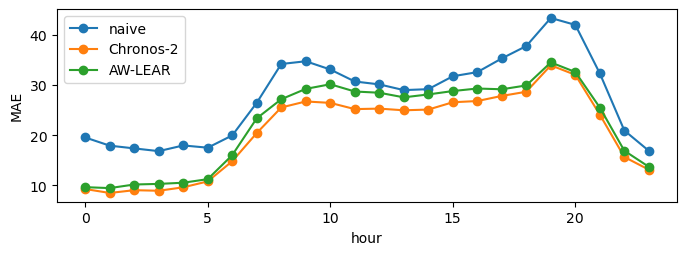

In [11]:
rows_all = np.array([IDX[t] for t in TDAYS])
if RUN_ALL:
    CHR2 = chronos_forecasts(P_, rows_all, 'amazon/chronos-2'); BOLT = chronos_forecasts(P_, rows_all, 'amazon/chronos-bolt-small')
else:
    CHR2, BOLT = Cc['chronos2'], Cc['chronos_bolt']
try:
    live = chronos_forecasts(P_, rows_all[:7], 'amazon/chronos-2')
    print('first 7 test days, max |live - cached| = %.3f EUR/MWh' % np.max(np.abs(live['median'] - CHR2['median'][:7])))
except Exception as e:
    print('Chronos not available here, using the cache:', e)
for k, F in [('naive', B['naive']), ('Chronos-Bolt', BOLT['median']), ('Chronos-2', CHR2['median']), ('AW-LEAR', B['aw_lear'])]:
    print(f'{k:13s} MAE {mae(F):6.2f}')
plt.figure(figsize=(8, 2.5))
for k, F in [('naive', B['naive']), ('Chronos-2', CHR2['median']), ('AW-LEAR', B['aw_lear'])]: plt.plot(np.mean(np.abs(A - F), 0), marker='o', label=k)
plt.xlabel('hour'); plt.ylabel('MAE'); plt.legend(); plt.show()

## §5 Honest comparison: scoreboard, Diebold–Mariano tests, combinations, compute cost

In [12]:
def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def dm(ea, eb, lags=7):
    """One-sided DM test (as in L2): H1 = model b more accurate than model a; loss = daily mean |error| over 24 hours."""
    dlt = np.mean(np.abs(ea), 1) - np.mean(np.abs(eb), 1)
    stat = dlt.mean() / np.sqrt(nw_var(dlt, lags) / len(dlt))
    return stat, 1 - stats.norm.cdf(stat)


M = dict(B)
if RUN_ALL:
    M['dnn'] = np.vstack(Parallel(n_jobs=N_JOBS)(delayed(lambda a, b: dnn_block(P_, L_, R_, F_, a, b, CFG_DNN, (1, 2, 3, 4))['pred'])(a, b) for a, b in MB))
    M['xgb'] = np.vstack(Parallel(n_jobs=N_JOBS)(delayed(lambda a, b: xgb_block(P_, L_, R_, F_, a, b, CFG_XGB)['pred'])(a, b) for a, b in MB))
else:
    M['dnn'] = np.vstack([r['pred'] for r in Cc['dnn_main']]); M['xgb'] = np.vstack([r['pred'] for r in Cc['xgb_main']])
M['bolt'], M['chr2'] = BOLT['median'], CHR2['median']
M['ens_ldx'] = (M['aw_lear'] + M['dnn'] + M['xgb']) / 3
M['ens_t4'] = np.mean([M['aw_arx'], M['aw_lear'], M['dnn'], M['xgb']], 0)
M['ens_lc'] = 0.5 * (M['aw_lear'] + M['chr2'])
E = {k: A - v for k, v in M.items()}
rows = []
for k in ['naive', 'aw_arx', 'aw_lear', 'ens4', 'gbm2', 'mlp2', 'xgb', 'dnn', 'bolt', 'chr2', 'ens_ldx', 'ens_t4', 'ens_lc']:
    rows.append([k, mae(M[k]), np.sqrt(np.mean(E[k] ** 2)), mae(M[k]) / mae(M['naive']), dm(E['aw_lear'], E[k])[1] if k != 'aw_lear' else np.nan])
print(pd.DataFrame(rows, columns=['model', 'MAE', 'RMSE', 'rMAE', 'DM p vs AW-LEAR']).round(3).to_string(index=False))

  model    MAE   RMSE  rMAE  DM p vs AW-LEAR
  naive 27.822 44.539 1.000            1.000
 aw_arx 22.303 36.339 0.802            0.203
aw_lear 22.533 36.346 0.810              NaN
   ens4 22.127 35.762 0.795            0.014
   gbm2 24.050 37.727 0.864            1.000
   mlp2 25.539 40.054 0.918            1.000
    xgb 23.260 36.942 0.836            0.984
    dnn 22.948 36.420 0.825            0.944
   bolt 22.154 35.654 0.796            0.220
   chr2 20.818 34.323 0.748            0.001
ens_ldx 21.972 35.424 0.790            0.001
 ens_t4 21.685 35.254 0.779            0.000
 ens_lc 20.813 34.106 0.748            0.000


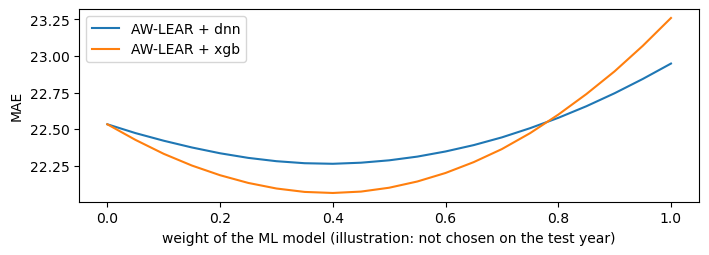

error correlation with AW-LEAR: {'dnn': np.float64(0.94), 'xgb': np.float64(0.89), 'chr2': np.float64(0.86)}
compute time for the test year, minutes on one core: XGBoost 2.6, DNN 2.7, Chronos-2 0.3, AW-LEAR 87.6


In [13]:
w = np.linspace(0, 1, 21)
plt.figure(figsize=(8, 2.5))
for k in ['dnn', 'xgb']: plt.plot(w, [mae(x * M[k] + (1 - x) * M['aw_lear']) for x in w], label='AW-LEAR + ' + k)
plt.xlabel('weight of the ML model (illustration: not chosen on the test year)'); plt.ylabel('MAE'); plt.legend(); plt.show()
print('error correlation with AW-LEAR:', {k: round(np.corrcoef(E['aw_lear'].ravel(), E[k].ravel())[0, 1], 2) for k in ['dnn', 'xgb', 'chr2']})
if not RUN_ALL:
    print('compute time for the test year, minutes on one core: XGBoost %.1f, DNN %.1f, Chronos-2 %.1f, AW-LEAR %.1f' % (
        sum(r['sec'] for r in Cc['xgb_main']) / 60, sum(r['sec'] for r in Cc['dnn_main']) / 60, Cc['chronos2']['sec'] / 60, Cc['lear_sec_day'] * 365 / 60))

## §6 Explaining the forecasts: SHAP values and permutation importance

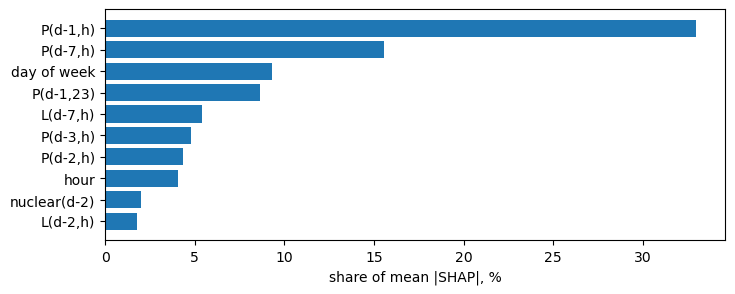

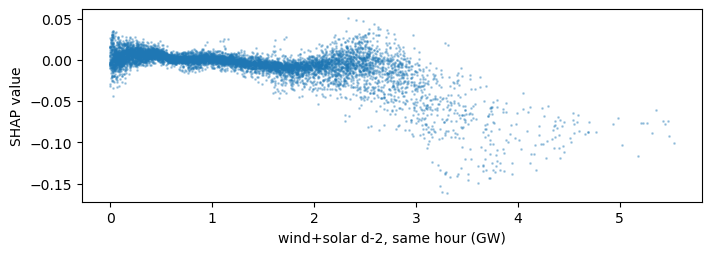

In [14]:
import xgboost as xgb
R6 = [xgb_block(P_, L_, R_, F_, a, b, CFG_XGB, shap=True) for a, b in MB] if RUN_ALL else Cc['xgb_main']
SH = np.concatenate([r['shap'] for r in R6], 0)        # days x 24 x (20 inputs + bias), asinh scale
share = np.abs(SH[:, :, :-1]).reshape(-1, 20).mean(0); share = share / share.sum() * 100
o = np.argsort(-share)[:10][::-1]
plt.figure(figsize=(8, 3)); plt.barh(range(10), share[o]); plt.yticks(range(10), [XGB_NAMES[j] for j in o])
plt.xlabel('share of mean |SHAP|, %'); plt.show()
XS = np.concatenate([r['X'] for r in R6], 0); j = XGB_NAMES.index('RES(d-2,h)')
plt.figure(figsize=(8, 2.5)); plt.scatter(XS[:, :, j].ravel() / 1000, SH[:, :, j].ravel(), s=1, alpha=0.3)
plt.xlabel('wind+solar d-2, same hour (GW)'); plt.ylabel('SHAP value'); plt.show()

In [15]:
if not RUN_ALL:
    rows_all = np.array([IDX[t] for t in TDAYS]); XM = [dnn_inputs(P_, L_, R_, F_, rows_all, r['sc'], CFG_DNN) for r in Cc['dnn_main']]
    names = XM[0][1]; base = mae(M['dnn']); rng = np.random.default_rng(SEED); perms = [rng.permutation(len(TDAYS)) for _ in range(5)]
    def perm_block(cols_):
        out = []
        for pm in perms:
            F = []
            for jm, (a, b) in enumerate(MB):
                X = XM[jm][0].copy(); X[:, cols_] = XM[jm][0][pm][:, cols_]; r = Cc['dnn_main'][jm]
                F.append(dnn_predict_from(r['models'], CFG_DNN, X[a - MB[0][0]:b - MB[0][0] + 1], r['mu'], r['sg'], r['sc']))
            out.append(mae(np.vstack(F)) - base)
        return np.mean(out)
    for blk in ['price d-1', 'price d-7', 'load', 'wind+solar', 'day of week']:
        print(f'{blk:12s} {perm_block(np.where(names == blk)[0]):+6.2f} EUR/MWh')

price d-1    +22.82 EUR/MWh


price d-7     +1.89 EUR/MWh
load          +2.12 EUR/MWh


wind+solar    -0.08 EUR/MWh


day of week   +3.66 EUR/MWh


## §7 Spikes and negative prices: classifiers, ROC curves and the cost–loss rule

In [16]:
THR_Q = 0.90


def spike_threshold(t):
    """Spike threshold for delivery days of the month starting at t: 90th percentile of the hourly prices of the 365 days before t."""
    w = PM_ALL.loc[t - pd.Timedelta(days=365):t - pd.Timedelta(days=1)].values.ravel()
    return float(np.quantile(w, THR_Q))


MONTH_START = {}
for _t in CAL:
    MONTH_START.setdefault(_t.to_period('M'), _t.replace(day=1))
THETA = np.array([spike_threshold(MONTH_START[t.to_period('M')]) for t in CAL])
CLF_NAMES = XGB_NAMES + ['threshold']
CLF_CFG = {'n_est': 400, 'eta': 0.05, 'depth': 4, 'mcw': 20, 'sub': 0.8, 'col': 0.8, 'lam': 1.0}


def clf_rows(Pa, La, Ra, Fa, rows, theta):
    X = gbm_rows(Pa, La, Ra, Fa, rows)
    th = np.repeat(theta[rows][:, None, None], 24, 1)
    return np.concatenate([X, th], 2)


def clf_block(Pa, La, Ra, Fa, theta, i0, i1, event, seed=SEED):
    """P(event) for rows i0..i1; event = 'spike' (price > threshold of its month) or 'neg' (price <= 0).
    XGBoost and a logistic regression (standardised features, one-hot hour and weekday), fitted on rows before the month."""
    import xgboost as xgb
    from sklearn.linear_model import LogisticRegression
    tr = np.arange(FIRST, i0)
    te = np.arange(i0, i1 + 1)
    Xtr, Xte = clf_rows(Pa, La, Ra, Fa, tr, theta).reshape(-1, len(CLF_NAMES)), clf_rows(Pa, La, Ra, Fa, te, theta).reshape(-1, len(CLF_NAMES))
    lab = (lambda r: (Pa[r] > theta[r][:, None])) if event == "spike" else (lambda r: (Pa[r] <= 0))
    ytr = lab(tr).ravel().astype(int)
    c = CLF_CFG
    mdl = xgb.XGBClassifier(n_estimators=c["n_est"], learning_rate=c["eta"], max_depth=c["depth"], min_child_weight=c["mcw"],
                            subsample=c["sub"], colsample_bytree=c["col"], reg_lambda=c["lam"], tree_method="hist", n_jobs=1,
                            random_state=seed, objective="binary:logistic").fit(Xtr, ytr)
    px = mdl.predict_proba(Xte)[:, 1].reshape(len(te), 24)

    def lin(X):
        num = np.delete(X, [18, 19], 1)
        return num, np.column_stack([np.eye(24)[X[:, 18].astype(int)], np.eye(7)[X[:, 19].astype(int)]])
    ntr, dtr = lin(Xtr)
    nte, dte = lin(Xte)
    mu, sg = ntr.mean(0), ntr.std(0)
    sg[sg == 0] = 1
    lr = LogisticRegression(C=1.0, max_iter=3000).fit(np.column_stack([(ntr - mu) / sg, dtr]), ytr)
    pl = lr.predict_proba(np.column_stack([(nte - mu) / sg, dte]))[:, 1].reshape(len(te), 24)
    return {"xgb": px, "logit": pl, "share_train": float(ytr.mean())}

In [17]:
from sklearn.metrics import roc_auc_score, roc_curve
RS = Parallel(n_jobs=N_JOBS)(delayed(clf_block)(P_, L_, R_, F_, THETA, a, b, 'spike') for a, b in MB) if RUN_ALL else Cc['clf_spike']
PS = np.vstack([r['xgb'] for r in RS]); PL = np.vstack([r['logit'] for r in RS])
TH = THETA[rows_all]; Y = (A > TH[:, None]).astype(int)
persist = (np.stack([P_[rows_all - k] for k in range(1, 8)]) > TH[None, :, None]).mean(0)
print('spike share in the test year: %.1f%%' % (100 * Y.mean()))
for k, sc in [('XGBoost', PS), ('logistic', PL), ('persistence', persist), ('AW-LEAR - theta', M['aw_lear'] - TH[:, None])]:
    print(f'{k:16s} AUC {roc_auc_score(Y.ravel(), sc.ravel()):.3f}')
a, b = MB[-1]; live = clf_block(P_, L_, R_, F_, THETA, a, b, 'spike')
if not RUN_ALL: print('live refit, max |difference| in probability:', np.max(np.abs(live['xgb'] - Cc['clf_spike'][-1]['xgb'])))
# cost-loss rule: act if probability > C / Lbar, value = sum over alerts of (P - theta - C)
C_ACT = 30.0; vr = np.array([IDX[t] for t in VDAYS]); PV, THV = P_[vr], THETA[vr][:, None]
LBAR = (PV - THV)[PV > THV].mean(); cut = C_ACT / LBAR; VALUE = A - TH[:, None] - C_ACT
print('C/L = %.3f; value per MW and year: %.1f thousand EUR (perfect foresight %.1f)' % (cut, VALUE[PS > cut].sum() / 1000, VALUE[VALUE > 0].sum() / 1000))

spike share in the test year: 22.1%
XGBoost          AUC 0.953
logistic         AUC 0.953


persistence      AUC 0.918
AW-LEAR - theta  AUC 0.959


live refit, max |difference| in probability: 0.0
C/L = 0.414; value per MW and year: 33.0 thousand EUR (perfect foresight 62.4)


## §8 Case study: the highest price of the test year

In [18]:
kd, kh = np.unravel_index(np.argmax(A), A.shape)
print('day', TDAYS[kd].date(), 'hour', kh, 'price %.2f' % A[kd, kh])
for k in ['naive', 'aw_lear', 'xgb', 'dnn', 'chr2']: print(f'{k:8s} forecast {M[k][kd, kh]:7.1f}')
print('spike probability (XGBoost): %.3f' % PS[kd, kh])
phi = SH[kd, kh, :-1]; y0 = SH[kd, kh, -1]; m_, s_ = R6[[i for i, (a, b) in enumerate(MB) if a <= rows_all[kd] <= b][0]]['m'], R6[[i for i, (a, b) in enumerate(MB) if a <= rows_all[kd] <= b][0]]['s']
P0, PH = m_ + s_ * np.sinh(y0), m_ + s_ * np.sinh(y0 + phi.sum()); phi_eur = phi * (PH - P0) / phi.sum()
for j in np.argsort(-np.abs(phi_eur))[:5]: print(f'{XGB_NAMES[j]:18s} value {XS[kd, kh, j]:8.1f}  contribution {phi_eur[j]:+7.1f} EUR/MWh')

day 2026-06-30 hour 20 price 954.59
naive    forecast   766.7
aw_lear  forecast   519.7
xgb      forecast   498.6
dnn      forecast   613.7
chr2     forecast   607.3
spike probability (XGBoost): 0.992
P(d-1,h)           value    766.7  contribution  +212.9 EUR/MWh
P(d-7,h)           value    493.0  contribution   +63.8 EUR/MWh
P(d-3,h)           value    374.2  contribution   +20.9 EUR/MWh
P(d-2,h)           value    241.9  contribution   +18.8 EUR/MWh
P(d-1,23)          value    210.3  contribution   +15.5 EUR/MWh


## §9 Pitfalls: look-ahead, shuffled cross-validation, data snooping, retraining

In [19]:
a, b = MB[-1]
hon = xgb_block(P_, L_, R_, F_, a, b, CFG_XGB)['pred']; lk = xgb_block(P_, L_, R_, F_, a, b, CFG_XGB, leak=True)['pred']
Am = P_[a:b + 1]
print('last month: honest MAE %.2f, with same-day load and wind+solar %.2f' % (np.mean(np.abs(Am - hon)), np.mean(np.abs(Am - lk))))
if not RUN_ALL:
    for k in ['xgb_leak', 'xgb_quarterly', 'xgb_once', 'xgb_roll365', 'xgb_roll730']:
        print(f'{k:14s} MAE {mae(np.vstack([r["pred"] for r in Cc[k]])):6.2f}')
    print('shuffled 5-fold   MAE %.2f' % mae(Cc['xgb_shuffled'][rows_all]))
    TD = np.array([mae(p) for p in Cc['dnn_test_all']])
    print('DNN: chosen on validation %.2f; best of %d settings on the test year %.2f (snooping)' % (TD[BEST_DNN], len(TD), TD.min()))
    print('Spearman correlation validation vs test: %.2f' % stats.spearmanr(VAL_DNN, TD)[0])

last month: honest MAE 33.69, with same-day load and wind+solar 36.92
xgb_leak       MAE  22.55
xgb_quarterly  MAE  23.77
xgb_once       MAE  24.25
xgb_roll365    MAE  25.59
xgb_roll730    MAE  24.45
shuffled 5-fold   MAE 22.01
DNN: chosen on validation 23.34; best of 25 settings on the test year 22.52 (snooping)
Spearman correlation validation vs test: 0.86


## §10 Leakage self-check

In [20]:
def corrupt(i, fill=np.nan):
    Pc, Lc, Rc = P_.copy(), L_.copy(), R_.copy(); Pc[i:] = fill; Lc[i - 1:] = fill; Rc[i - 1:] = fill
    raw = FUND_RAW.copy(); raw.loc[CAL[i - 1]:] = fill
    return Pc, Lc, Rc, raw.ffill().shift(2).reindex(CAL).values.astype(float)
a = MB[-1][0]
for fill in (np.nan, 1e4):
    g = xgb_block(*corrupt(a, fill), a, a, CFG_XGB)['pred'][0]
    print('fill', fill, '-> max |difference| XGBoost: %.2e' % np.max(np.abs(g - M['xgb'][a - MB[0][0]])))

fill nan -> max |difference| XGBoost: 0.00e+00


fill 10000.0 -> max |difference| XGBoost: 0.00e+00


## Exercises
1. Change the validation year to the 6 months before the test year: does the chosen setting change? Does the test MAE?
2. Add AW-ARX to the LEAR + Chronos-2 combination. Is the gain significant (DM test)?
3. Set the action cost C to 60 EUR/MWh in §7. How many alerts are left, and what is the value per MW?
4. Replace the spike threshold (90th percentile) by a fixed 200 EUR/MWh. How do the AUC values change?